![Python Banner](../../Image/05_02_meta_learners.png)


# 2.2. Meta-Learners with Multiple Discrete Treatments


## Overview

Meta-learners extend naturally from the binary setting to the case of **multiple discrete treatments**, where each unit receives exactly one of $K \geq 2$ mutually exclusive treatment arms. Denoting the treatment variable as $T \in \{0, 1, \dots, K-1\}$, with $T = 0$ designated as the control or reference arm, the estimand of interest becomes a set of $K - 1$ pairwise contrasts against control:

$$\tau_k(x) = \mathbb{E}[Y(k) - Y(0) \mid X = x], \quad k = 1, \dots, K-1$$

where $Y(k)$ denotes the potential outcome under treatment arm $k$. This family of CATE functions characterizes how the effect of each active treatment, relative to control, varies across the covariate space. In principle, one could also target pairwise contrasts between active arms, $\mathbb{E}[Y(k) - Y(k') \mid X = x]$ for $k \neq k'$, though the contrast-versus-control framing is most common in applied work and maps cleanly onto the meta-learner machinery developed for the binary case.

The multi-arm setting introduces several challenges that do not arise — or arise less acutely — with binary treatments.

**Multinomial propensity scores.** When treatment is assigned among $K$ arms, the propensity score generalizes to a vector of conditional probabilities:

$$\mathbf{e}(x) = \left( e_0(x), e_1(x), \dots, e_{K-1}(x) \right), \quad e_k(x) = P(T = k \mid X = x), \quad \sum_{k=0}^{K-1} e_k(x) = 1$$

Estimation of $\mathbf{e}(x)$ requires a **multinomial classification model** — such as multinomial logistic regression, softmax-output gradient boosting, or a multiclass random forest — rather than a single binary classifier. The arm-specific probabilities $e_k(x)$ enter directly into doubly robust and propensity-weighted estimators (X-Learner, R-Learner, DR-Learner), and their quality has a first-order impact on CATE estimation accuracy. In some designs, particularly when active arms are defined post hoc by splitting a treated group, binary propensity scores for "any treatment" may suffice, but this approximation should be used with care.

**Arm-level overlap and sparsity.** A critical assumption for identification is **positivity** (or overlap): for each arm $k$,

$$e_k(x) > 0 \quad \text{for all } x \text{ in the support of } X$$

With many arms, positivity violations become more likely simply because each arm captures a smaller fraction of the sample. Sparse treatment arms — those with few observations — lead to poorly estimated outcome models and propensity scores for that arm, inflating the variance of the corresponding CATE estimates. Practitioners should routinely inspect the marginal distribution of arm sizes and the effective sample size available for each arm-specific model fit.

**Covariate overlap across arms.** Even when each arm has adequate marginal sample size, the covariate distributions across arms may diverge substantially. This is particularly relevant in observational studies where treatment selection is strongly confounded. For each pairwise contrast $\tau_k(x)$, overlap diagnostics — such as the distribution of $e_k(x) / e_0(x)$ or standardized mean differences in $X$ between arm $k$ and control — should be examined before trusting CATE estimates in regions of thin support.

### Adapting Meta-Learner Variants to the Multi-Arm Setting

Each meta-learner from the binary case extends to $K$ arms, though the adaptations vary in complexity.

**S-Learner.** A single outcome model $\hat{\mu}(x, t)$ is fit on the full sample with $T$ encoded as a categorical feature (via dummy coding or an embedding). The CATE for arm $k$ is recovered as:

$$\hat{\tau}_k^S(x) = \hat{\mu}(x, k) - \hat{\mu}(x, 0)$$

This is the simplest extension and inherits the same weakness as in the binary case: tree-based base learners may fail to adequately represent the treatment dimension when treatment effects are small relative to outcome variation.

**T-Learner.** Separate outcome models $\hat{\mu}_k(x)$ are fit on each arm's subsample independently, and the CATE is estimated as:

$$\hat{\tau}_k^T(x) = \hat{\mu}_k(x) - \hat{\mu}_0(x)$$

This requires fitting $K$ models in total. The approach is straightforward but amplifies the imbalance problem: with $K$ arms of roughly equal size, each arm-specific model is trained on approximately $1/K$ of the data, which can severely degrade performance for large $K$ or small total sample sizes.

**X-Learner.** The cross-fitting logic extends arm by arm: for each active arm $k$, the binary X-Learner pipeline is run using arm $k$ and the control arm as the two groups, with the arm-specific propensity score $e_k(x)$ used for weighting. This produces $K - 1$ independent CATE estimates $\hat{\tau}_k^X(x)$. The X-Learner's efficiency advantage under imbalance carries over directly and is particularly valuable here, since each arm-versus-control comparison may involve substantially unequal group sizes.

**R-Learner.** The Robinson decomposition generalizes by residualizing against arm-specific nuisance functions. For each contrast $k$ versus $0$, one restricts attention to units with $T \in \{0, k\}$ and applies the standard binary R-Learner, or alternatively uses a fully multivariate formulation that residualizes outcomes against $\hat{\mu}(x) = \mathbb{E}[Y \mid X]$ and treatments against their multinomial propensity predictions. The orthogonalization property carries over, making the R-Learner relatively robust to nuisance model misspecification in each arm-specific estimation problem.

**DR-Learner.** The doubly robust AIPW pseudo-outcome for contrast $k$ versus $0$ generalizes to:

$$\hat{\phi}_i^k = \frac{\mathbf{1}[T_i = k](Y_i - \hat{\mu}_k(X_i))}{e_k(X_i)} - \frac{\mathbf{1}[T_i = 0](Y_i - \hat{\mu}_0(X_i))}{e_0(X_i)} + \hat{\mu}_k(X_i) - \hat{\mu}_0(X_i)$$

A separate regression of $\hat{\phi}_i^k$ on $X_i$ yields the CATE estimate for arm $k$. The doubly robust property holds arm by arm: each $\hat{\tau}_k^{DR}(x)$ is consistent if either the outcome model for arm $k$ or the propensity scores $e_k(x)$ and $e_0(x)$ are correctly specified. Cross-fitting across arms is essential to avoid overfitting bias in the pseudo-outcome construction.

### Practical Considerations

The choice among meta-learners in the multi-arm setting follows the same logic as in the binary case, with additional weight given to arm-level sample sizes and propensity score quality. A few practical guidelines:

- When arm sizes are roughly balanced and the number of arms $K$ is small, the **T-Learner** is a reasonable baseline.
- When arm sizes are unequal — which is common in observational studies — the **X-Learner** or **DR-Learner** is preferred for its efficiency and robustness.
- When propensity score estimation is reliable and statistical inference on $\tau_k(x)$ is required, the **DR-Learner** provides formal asymptotic guarantees.
- The **R-Learner** is attractive when confounding is a primary concern and one wishes to minimize the impact of nuisance model misspecification through orthogonalization.
- Regardless of learner choice, arm-level overlap diagnostics and effective sample size checks should precede any CATE estimation in the multi-arm setting.


## Part 0: PyCausalML — multiple discrete treatments

For the binary DGP we use **`simulate_nuisance_and_easy_treatment()`**, which matches **`synthetic_data(mode = 1, ...)`** in `R/dataset.R` (difficult nuisance, easy treatment). The exported name `synthetic_data()` in this package may refer to a **mode-2-only** generator (`R/synthetic_data.R`); calling the explicit simulator avoids ambiguity. We then randomly assign treated units to arm `1` or `2` (80% / 20%), giving control (`0`), treatment_a (`1`), treatment_b (`2`).

**Note:** Arms are created *after* the binary DGP, so the latent effect `tau` is the same for both arms; do not interpret overlap plots or RMSE here as a benchmark for multi-arm DGP design. For known arm-specific CATEs and multinomial propensities, use **Part A**.

### Generate synthetic data

#### Simulate nuisance-and-easy treatment and split treated units into two arms


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
try:
    import pycausalml  # noqa: F401
    import causaldata  # noqa: F401
    import matplotlib  # noqa: F401
    import xgboost  # noqa: F401
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
        "statsmodels", "causaldata",
    ])
print("PyCausalML ready.")

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

from pycausalml import (
    DRLearner,
    DomainAdaptationLearner,
    LinearDML,
    RLearner,
    SLearner,
    SparseLinearDML,
    TLearner,
    XLearner,
    explain_cate,
    synthetic_data,
)
from pycausalml.data import make_multiarm_data
from pycausalml.double_machine_learning import CausalForestDML, PartiallyLinearDML

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
N_EST = 25
print("Imported PyCausalML")

def ate_row(name, model, X):
    cate = np.asarray(model.predict(X), dtype=float)
    info = model.average_treatment_effect(X)
    est = float(info["estimate"])
    se = float(info["std.err"])
    if not np.isfinite(se):
        se = float(np.std(cate, ddof=1) / np.sqrt(len(cate)))
        est = float(np.mean(cate))
    return {
        "learner": name,
        "ate": est,
        "se": se,
        "ci_lower": est - 1.96 * se,
        "ci_upper": est + 1.96 * se,
    }

def abs_pct_ate(pred, truth):
    denom = abs(float(np.mean(truth)))
    if denom < 1e-8:
        return np.nan
    return 100.0 * abs(float(np.mean(pred) - np.mean(truth))) / denom

def kl_divergence(pred, truth, bins=15):
    pred = np.asarray(pred, dtype=float)
    truth = np.asarray(truth, dtype=float)
    lo = float(min(pred.min(), truth.min()))
    hi = float(max(pred.max(), truth.max()))
    if not np.isfinite(lo) or hi <= lo:
        return np.nan
    hp, _ = np.histogram(pred, bins=bins, range=(lo, hi))
    hq, _ = np.histogram(truth, bins=bins, range=(lo, hi))
    hp = hp.astype(float) + 1e-3
    hq = hq.astype(float) + 1e-3
    hp /= hp.sum()
    hq /= hq.sum()
    return float(np.sum(hp * np.log(hp / hq)))

def cumulative_gain(y, w, score):
    order = np.argsort(-np.asarray(score, dtype=float))
    y = np.asarray(y, dtype=float)[order]
    w = np.asarray(w)[order]
    n = len(y)
    frac = np.arange(1, n + 1) / n
    gain = np.empty(n)
    for i in range(n):
        ww = w[: i + 1]
        yy = y[: i + 1]
        n1 = int((ww == 1).sum())
        n0 = int((ww == 0).sum())
        gain[i] = 0.0 if n1 == 0 or n0 == 0 else (yy[ww == 1].mean() - yy[ww == 0].mean()) * (i + 1) / n
    return frac, gain

def tutorial_file(name: str) -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("Tutorials") / "05_02_Meta_Learners" / "data" / name,
            Path("data") / name,
        ):
            path = cand / rel
            if path.is_file():
                return path
    raise FileNotFoundError(name)

base = synthetic_data(mode=2, n=900, p=6, sigma=1.0, random_state=1)
X0, y0, tau0 = base["X"], base["y"], base["tau"]
w0 = base["w"].copy()
treated = np.flatnonzero(w0 == 1)
pick = np.random.default_rng(1).choice(treated, size=int(0.2 * len(treated)), replace=False)
w0[pick] = 2
names0 = [f"X{i+1}" for i in range(X0.shape[1])]
print("Arm counts", {int(a): int((w0 == a).sum()) for a in np.unique(w0)})
print("Latent tau is shared across arms in Part 0; mean", round(float(tau0.mean()), 3))


PyCausalML ready.


Imported PyCausalML
Arm counts {0: 425, 1: 380, 2: 95}
Latent tau is shared across arms in Part 0; mean 0.47


### S-Learner (multiple treatments)

`SLearner` supports multiple arms: one contrast per non-control level. `predict()` returns a matrix with one column per treatment arm vs control.

#### ATE


#### ATE with confidence intervals


#### ATE with bootstrap CIs

Use `estimate_ate(learner_s_m, X2, treatment_multi, y2, return_ci = TRUE, bootstrap_ci = TRUE, n_bootstraps = 100L, bootstrap_size = 5000L)` for a full bootstrap (fewer iterations for quick tests).

#### CATE


#### CATE with confidence intervals

Use `fit_predict(learner_s_m, X2, treatment_multi, y2, return_ci = TRUE, ...)`; returned objects include `te`, `te_lower`, `te_upper` (matrices when multiple arms).

### T-Learner (multiple treatments)

`TLearner` is binary in **PyCausalML**; fit one learner per arm (control vs 1, control vs 2).

#### ATE with confidence intervals


#### CATE


#### CATE with confidence intervals

Use `fit_predict(learner_s_m, X2, treatment_multi, y2, return_ci = TRUE, ...)`; returned objects include `te`, `te_lower`, `te_upper` (matrices when multiple arms).

### T-Learner (multiple treatments)

`TLearner` is binary in **PyCausalML**; fit one learner per arm (control vs 1, control vs 2).

#### ATE with confidence intervals


#### ATE without propensity


#### CATE


#### CATE without propensity (X-Learner)


### R-Learner (multiple treatments)

One **R-Learner** per arm (`n_fold` as in binary case).

#### ATE with / without propensity


#### ATE without propensity (R-Learner)


#### CATE


#### CATE without propensity (R-Learner)


### Visualize (multiple treatments)

#### Overlaid CATE histograms (T / X / R vs true `tau`)


### Summary table (multiple treatment ATE)

#### ATE comparison table (S / T / X / R)


        learner   ate    se  ci_lower  ci_upper  true_ate
S-Learner arm 1 0.078 0.004     0.071     0.086     0.463
T-Learner arm 1 0.378 0.025     0.330     0.427     0.463
X-Learner arm 1 0.361 0.019     0.325     0.398     0.463
R-Learner arm 1 0.392 0.087     0.221     0.563     0.463
S-Learner arm 2 0.055 0.003     0.050     0.060     0.432
T-Learner arm 2 0.372 0.029     0.316     0.429     0.432
X-Learner arm 2 0.331 0.025     0.282     0.379     0.432
R-Learner arm 2 0.702 0.341     0.035     1.370     0.432


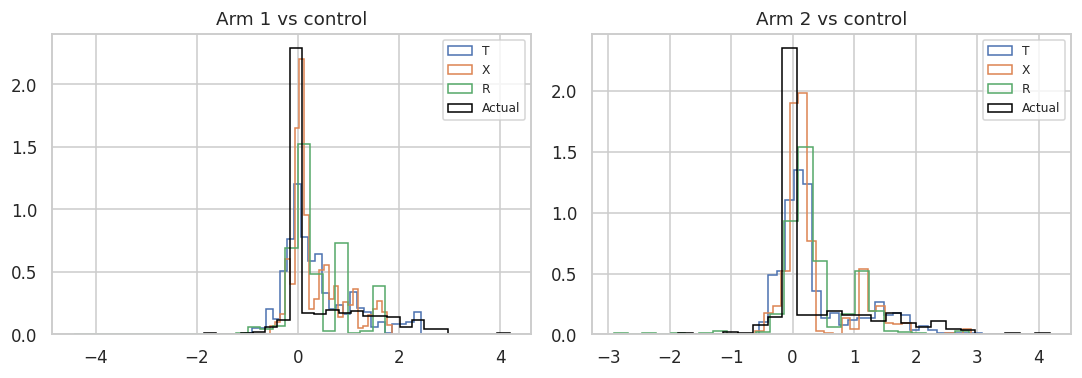

In [2]:
def contrast(X, w, y, arm, control=0):
    mask = (w == control) | (w == arm)
    return X[mask], (w[mask] == arm).astype(int), y[mask]

rows = []
fitted_part0 = {}
for arm in (1, 2):
    Xc, wc, yc = contrast(X0, w0, y0, arm)
    for label, cls in (("S", SLearner), ("T", TLearner), ("X", XLearner), ("R", RLearner)):
        model = cls(learner="gbr", n_estimators=N_EST, random_state=arm)
        model.fit(Xc, wc, yc, feature_names=names0)
        fitted_part0[(label, arm)] = (model, Xc)
        row = ate_row(f"{label}-Learner arm {arm}", model, Xc)
        row["true_ate"] = float(tau0[(w0 == 0) | (w0 == arm)].mean())
        rows.append(row)
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, arm in zip(axes, (1, 2)):
    for label in ("T", "X", "R"):
        model, Xc = fitted_part0[(label, arm)]
        ax.hist(model.predict(Xc), bins=25, histtype="step", density=True, label=label)
    ax.hist(tau0[(w0 == 0) | (w0 == arm)], bins=25, histtype="step", density=True, color="black", label="Actual")
    ax.set_title(f"Arm {arm} vs control")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


---

## Part A: Synthetic data, problem formulation, X- and DR-learners

### Generate synthetic multi-arm data

We simulate $K=3$ arms with multinomial assignment, known $\tau_1(x)$, $\tau_2(x)$ versus control, and store true propensities for diagnostics.

#### DGP function and draw `df_multi`


In [3]:
draw = make_multiarm_data(n=900, random_state=11)
Xa, ya, wa = draw["X"], draw["y"], draw["w"]
tau1, tau2 = draw["tau1"], draw["tau2"]
names_a = [f"X{i+1}" for i in range(Xa.shape[1])]
print("Arm counts", {int(a): int((wa == a).sum()) for a in np.unique(wa)})
print("True mean contrasts", round(float(tau1.mean()), 3), round(float(tau2.mean()), 3))


Arm counts {0: 294, 1: 305, 2: 301}
True mean contrasts 1.01 -0.396


### Problem formulation

For $K$ arms ($T \in \{0,1,\dots,K-1\}$), we estimate **$K-1$ CATE functions** relative to control ($T=0$):

$$\tau_k(x) = \mathbb{E}[Y(k) - Y(0) \mid X = x], \quad k = 1,\dots,K-1$$

Challenges include **multinomial propensities** $e_k(x) = P(T=k \mid X=x)$, **sparse arms**, and careful **cross-fitting** when you split data (illustrated in Part B).

### X-Learner extension for multiple treatments

We extend the X-learner using outcome models per arm, imputed treatment effects, propensity-based weights, and a CATE regression per non-control arm (`learner="rf"`).

#### Multi-arm X-Learner implementation and in-sample RMSE


### DR-Learner for multiple treatments

Doubly robust scores use **estimated** multinomial propensities and outcome models per arm; we regress the score on $X$ for each contrast vs. control.

#### Multi-arm DR-Learner implementation and in-sample RMSE


In [4]:
arm_models = {}
cmp_rows = []
truth = {1: tau1, 2: tau2}
for arm in (1, 2):
    Xc, wc, yc = contrast(Xa, wa, ya, arm)
    true = truth[arm][(wa == 0) | (wa == arm)]
    for label, cls in (("X", XLearner), ("DR", DRLearner), ("T", TLearner), ("R", RLearner)):
        model = cls(learner="gbr", n_estimators=N_EST, random_state=10 + arm)
        model.fit(Xc, wc, yc, feature_names=names_a)
        pred = model.predict(Xc)
        arm_models[(label, arm)] = model
        cmp_rows.append({
            "learner": label,
            "arm": arm,
            "ate": float(np.mean(pred)),
            "true_ate": float(np.mean(true)),
            "rmse": float(np.sqrt(np.mean((pred - true) ** 2))),
        })
print(pd.DataFrame(cmp_rows).round(3).to_string(index=False))


learner  arm    ate  true_ate  rmse
      X    1  1.020     1.007 0.162
     DR    1  1.016     1.007 0.148
      T    1  1.036     1.007 0.206
      R    1  1.013     1.007 0.170
      X    2 -0.416    -0.421 0.100
     DR    2 -0.401    -0.421 0.142
      T    2 -0.438    -0.421 0.137
      R    2 -0.407    -0.421 0.140


### Visualization: heterogeneity across arms

#### Smoothed true vs estimated CATE by arm (vs. `X1`)


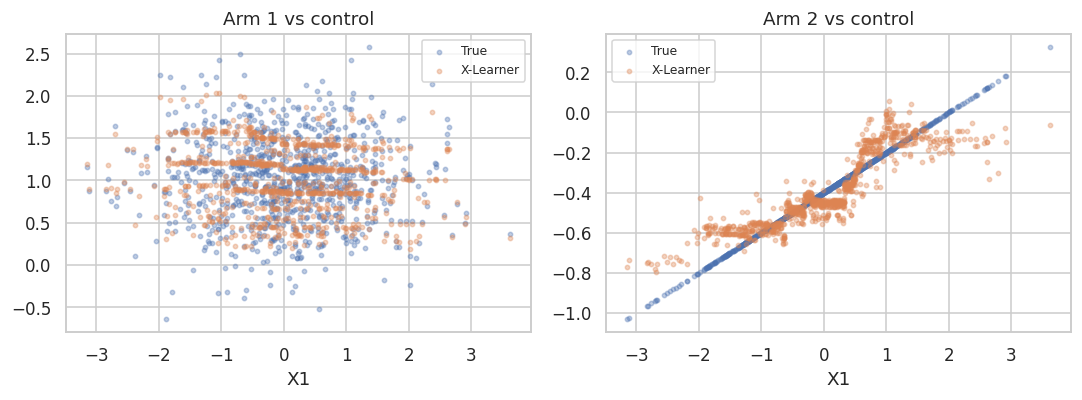

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
order = np.argsort(Xa[:, 0])
for ax, arm, truth_arm in ((axes[0], 1, tau1), (axes[1], 2, tau2)):
    model = arm_models[("X", arm)]
    pred = model.predict(Xa)
    ax.scatter(Xa[order, 0], truth_arm[order], s=8, alpha=0.35, label="True")
    ax.scatter(Xa[order, 0], pred[order], s=8, alpha=0.35, label="X-Learner")
    ax.set_xlabel("X1")
    ax.set_title(f"Arm {arm} vs control")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## Part B: Diagnostics, validation, and learner comparison

### Holdout RMSE (X-Learner vs DR-Learner)

We split units into train and validation sets, fit both pipelines on the training set only, and report **RMSE** of $\hat{\tau}_k$ vs. true $\tau_k$ on the validation rows (mirrors the train/validation spirit of notebook 02).

#### Train–validation split and RMSE table


In [6]:
rng = np.random.default_rng(24)
hold = rng.choice(len(ya), size=int(0.3 * len(ya)), replace=False)
train = np.setdiff1d(np.arange(len(ya)), hold)
hold_rows = []
for arm in (1, 2):
    mask = (wa == 0) | (wa == arm)
    tr = train[mask[train]]
    te = hold[mask[hold]]
    Xtr, wtr, ytr = Xa[tr], (wa[tr] == arm).astype(int), ya[tr]
    Xte = Xa[te]
    true = truth[arm][te]
    for label, cls in (("X", XLearner), ("DR", DRLearner)):
        model = cls(learner="gbr", n_estimators=N_EST, random_state=24)
        model.fit(Xtr, wtr, ytr, feature_names=names_a)
        pred = model.predict(Xte)
        hold_rows.append({
            "learner": label, "arm": arm,
            "rmse": float(np.sqrt(np.mean((pred - true) ** 2))),
        })
print(pd.DataFrame(hold_rows).round(3).to_string(index=False))


learner  arm  rmse
      X    1 0.149
     DR    1 0.198
      X    2 0.123
     DR    2 0.183


### Overlap diagnostics

For multiple arms, overlap means each arm has sufficient probability mass across the covariate space; we check that no propensity $e_k(x)$ is too close to 0 or 1.

#### Propensity histograms and trimming counts


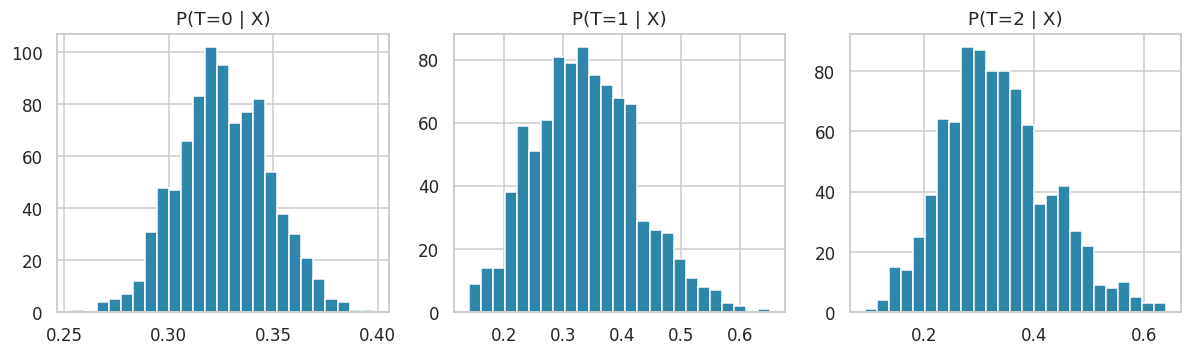

Share of scores outside (0.05, 0.95):
0 0.0
1 0.0
2 0.0


In [7]:
from sklearn.linear_model import LogisticRegression
prop_model = LogisticRegression(max_iter=400)
# one-vs-rest propensities on the full sample
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, arm in zip(axes, (0, 1, 2)):
    clf = LogisticRegression(max_iter=400)
    clf.fit(Xa, (wa == arm).astype(int))
    score = clf.predict_proba(Xa)[:, 1]
    ax.hist(score, bins=25, color="#2E86AB")
    ax.set_title(f"P(T={arm} | X)")
fig.tight_layout()
plt.show()
print("Share of scores outside (0.05, 0.95):")
for arm in (0, 1, 2):
    clf = LogisticRegression(max_iter=400).fit(Xa, (wa == arm).astype(int))
    score = clf.predict_proba(Xa)[:, 1]
    print(arm, round(float(((score < 0.05) | (score > 0.95)).mean()), 3))


### Balance assessment (before / after weighting)

Standardized mean differences (SMD) for each treatment arm vs. control, before and after multinomial IPW-style weighting (same spirit as balance checks in notebook 02).

#### SMD bar chart (unweighted vs IPW)


 arm covariate    smd  smd_ipw
   1        X1  0.208   -0.716
   1        X2  0.044    0.094
   1        X3  0.135    0.119
   2        X1 -0.313    0.685
   2        X2  0.037    0.019
   2        X3  0.007   -0.083


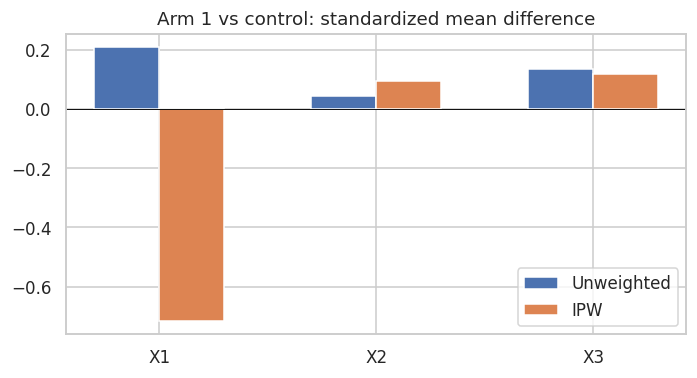

In [8]:
def smd(x, mask_t, mask_c, weights=None):
    xt, xc = x[mask_t], x[mask_c]
    if weights is None:
        wt, wc = np.ones(len(xt)), np.ones(len(xc))
    else:
        wt, wc = weights[mask_t], weights[mask_c]
    mt = np.average(xt, weights=wt)
    mc = np.average(xc, weights=wc)
    vt = np.average((xt - mt) ** 2, weights=wt)
    vc = np.average((xc - mc) ** 2, weights=wc)
    return (mt - mc) / np.sqrt(0.5 * (vt + vc) + 1e-8)

# multinomial logit weights
logits = np.column_stack([
    np.zeros(len(Xa)),
    Xa[:, 0],
    -Xa[:, 0],
])
logits -= logits.max(axis=1, keepdims=True)
prob = np.exp(logits)
prob /= prob.sum(axis=1, keepdims=True)
ipw = np.ones(len(Xa))
for arm in (1, 2):
    ipw[wa == arm] = prob[wa == arm, 0] / np.clip(prob[wa == arm, arm], 1e-3, None)
rows = []
for arm in (1, 2):
    for j, name in enumerate(names_a):
        rows.append({
            "arm": arm, "covariate": name,
            "smd": smd(Xa[:, j], wa == arm, wa == 0),
            "smd_ipw": smd(Xa[:, j], wa == arm, wa == 0, ipw),
        })
smd_df = pd.DataFrame(rows)
print(smd_df.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
plot_s = smd_df[smd_df.arm == 1]
ax.bar(np.arange(len(plot_s)) - 0.15, plot_s.smd, width=0.3, label="Unweighted")
ax.bar(np.arange(len(plot_s)) + 0.15, plot_s.smd_ipw, width=0.3, label="IPW")
ax.set_xticks(np.arange(len(plot_s)))
ax.set_xticklabels(plot_s.covariate)
ax.axhline(0, color="black", lw=0.6)
ax.set_title("Arm 1 vs control: standardized mean difference")
ax.legend()
fig.tight_layout()
plt.show()


### CATE calibration (X-Learner vs. ground truth)

Binned average of estimated CATE vs. true CATE for each non-control arm.

#### Calibration panels (X-Learner vs ground truth)


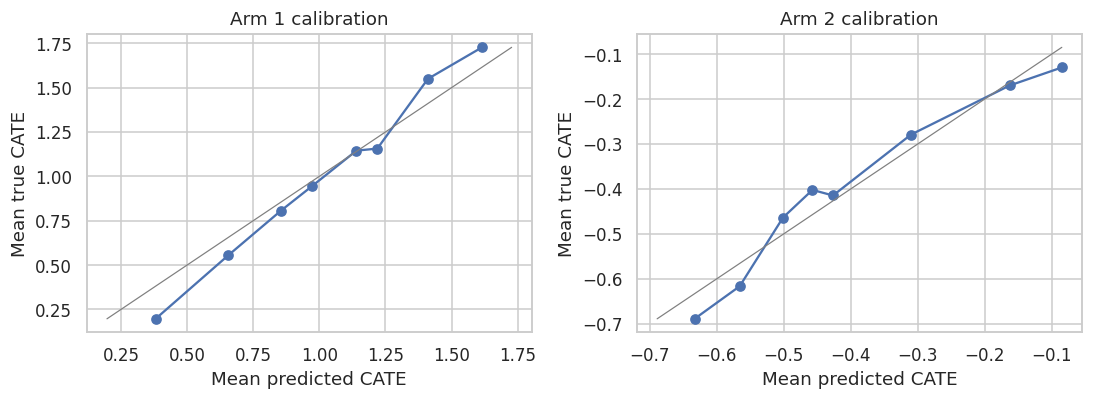

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, arm, truth_arm in ((axes[0], 1, tau1), (axes[1], 2, tau2)):
    pred = arm_models[("X", arm)].predict(Xa)
    bins = pd.qcut(pred, 8, duplicates="drop")
    tab = pd.DataFrame({"pred": pred, "true": truth_arm, "bin": bins}).groupby("bin", observed=True).mean()
    ax.plot(tab.pred, tab.true, marker="o")
    lim = [min(tab.pred.min(), tab.true.min()), max(tab.pred.max(), tab.true.max())]
    ax.plot(lim, lim, color="grey", lw=0.8)
    ax.set_title(f"Arm {arm} calibration")
    ax.set_xlabel("Mean predicted CATE")
    ax.set_ylabel("Mean true CATE")
fig.tight_layout()
plt.show()


### Decision framework: which meta-learner?

#### Example heuristic `select_meta_learner_multi()`


## Part C: SHAP and interpretability (PyCausalML per-arm X-Learner)

[SHAP](https://github.com/shap/shap) summarizes how each covariate contributes to **predicted** CATE $\hat{\tau}(X)$ for a fitted model. Notebook 02 uses ``explain_cate()`` with binary S/T/X/R learners. With $K>2$ arms, **PyCausalML** fits one **X-Learner** per contrast (control vs. arm $k$); we illustrate **XGBoost** base learners and **permutation SHAP** for arm 1 and arm 2 (same workflow as Part C in notebook 02).


### SHAP: fit per-arm X-Learners (XGBoost)


In [10]:
explanations = {}
for arm in (1, 2):
    Xc, wc, yc = contrast(Xa, wa, ya, arm)
    model = XLearner(learner="xgb", n_estimators=N_EST, random_state=arm)
    model.fit(Xc, wc, yc, feature_names=names_a)
    explanations[arm] = explain_cate(model, Xc, max_samples=20, n_permutations=5, random_state=arm)
    print("Arm", arm, np.round(explanations[arm].importance(), 3))


Arm 1 [0.037 0.328 0.005]
Arm 2 [0.2   0.016 0.013]


### SHAP: permutation values with `` parallel backend


### SHAP: beeswarm importance plots


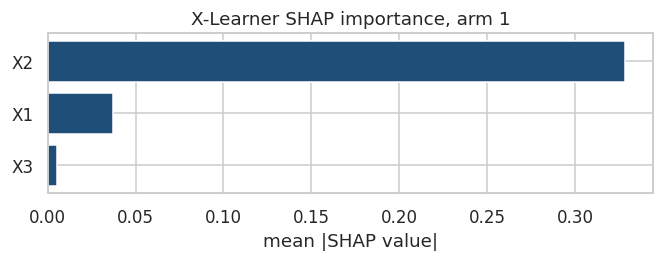

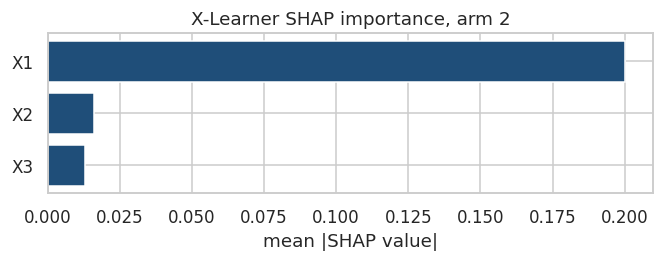

In [11]:
for arm, exp in explanations.items():
    exp.plot_importance(title=f"X-Learner SHAP importance, arm {arm}")
    plt.show()


## Part D: Use case with Lung data set

The **`lung`** data from **`this tutorial (`data/lung.csv`)`** describe advanced lung cancer patients (covariates such as age, sex, and ECOG performance status; observed survival **`time`**). There is **no** treatment column in the published data. For a **three-arm** illustration we **simulate** assignment and a **secondary binary outcome**, following the same recipe as in [09-multi-arm-causal-boost-r.qmd](../01-tree-based-Models/09-multi-arm-causal-boost-r.qmd):

- **`placebo`** (baseline), **`A`**, **`B`**: multinomial assignment with probabilities $(0.4, 0.3, 0.3)$.
- **`log_time`**: $\log(\texttt{time})$ as a continuous outcome (positive times only; rows with missing **`time`** are dropped).
- **`health_status`**: Bernoulli draw with baseline probability $0.3$, increased by $0.10$ on arm **A** and $0.15$ on arm **B** (treatment-dependent probabilities).

**PyCausalML** meta-learners expect a **numeric** control code **`0`** when `control_name = 0` (factors are coerced to $1,\ldots,K$ internally). Below we keep human-readable labels in **`treatment_arm`** and map **`placebo` $\to 0`**, **`A` $\to 1`**, **`B` $\to 2`** in **`treatment`** for fitting.

### Build `lung` analysis tibble

#### Simulated arms, outcomes, covariates, and summary tables


In [12]:
lung = pd.read_csv(tutorial_file("lung.csv"))
lung = lung.dropna(subset=["age", "sex", "ph.ecog", "time"]).copy()
lung = lung[lung["time"] > 0]
rng = np.random.default_rng(123)
lung["treatment"] = rng.choice([0, 1, 2], size=len(lung), p=[0.4, 0.3, 0.3])
lung["health_status"] = rng.binomial(
    1, 0.30 + 0.10 * (lung["treatment"] == 1) + 0.15 * (lung["treatment"] == 2)
)
lung["log_time"] = np.log(lung["time"])
X_lung = lung[["age", "sex", "ph.ecog"]].to_numpy(dtype=float)
w_lung = lung["treatment"].to_numpy(dtype=int)
lung_names = ["age", "sex", "ph.ecog"]
print(lung["treatment"].value_counts().sort_index().to_string())
print(lung.groupby("treatment")[["health_status", "log_time"]].mean().round(3))


treatment
0    97
1    66
2    64
           health_status  log_time
treatment                         
0                  0.402     5.508
1                  0.348     5.438
2                  0.453     5.296


### S-, T-, X-, and R-Learners on `log_time` and `health_status`

As in **Part 0**, **`TLearner`**, **`XLearner`**, and **`RLearner`** are **binary** in **PyCausalML**: we fit **one model per contrast** (placebo vs **A**, placebo vs **B**). **`SLearner`** uses a single surface with a treatment indicator per contrast. Simulated assignment does **not** depend on **`X`**, so we fit **X-** and **R-Learners without an external propensity vector** (`p` omitted); in observational settings you would pass estimated propensities when appropriate.

For **`health_status`**, random forests uses squared-error loss as a simple tutorial default (not a calibrated probability model).

#### S-Learner: fit and ATE with CIs (`log_time`, `health_status`)


#### T-, X-, and R-Learners: fits and combined ATE table


In [13]:
def lung_table(y, outcome):
    rows = []
    for arm, contrast_name in ((1, "A vs placebo"), (2, "B vs placebo")):
        Xc, wc, yc = contrast(X_lung, w_lung, y, arm)
        for label, cls in (("S", SLearner), ("T", TLearner), ("X", XLearner), ("R", RLearner)):
            model = cls(learner="gbr", n_estimators=N_EST, random_state=3)
            model.fit(Xc, wc, yc, feature_names=lung_names)
            row = ate_row(f"{label}-Learner", model, Xc)
            row["outcome"] = outcome
            row["contrast"] = contrast_name
            rows.append(row)
    return pd.DataFrame(rows)

lung_ate = pd.concat([
    lung_table(lung["log_time"].to_numpy(dtype=float), "log_time"),
    lung_table(lung["health_status"].to_numpy(dtype=float), "health_status"),
], ignore_index=True)
print(lung_ate.round(3).to_string(index=False))


  learner    ate    se  ci_lower  ci_upper       outcome     contrast
S-Learner  0.000 0.000     0.000     0.000      log_time A vs placebo
T-Learner -0.078 0.024    -0.124    -0.031      log_time A vs placebo
X-Learner -0.088 0.018    -0.124    -0.052      log_time A vs placebo
R-Learner -0.043 0.163    -0.363     0.276      log_time A vs placebo
S-Learner -0.036 0.001    -0.039    -0.034      log_time B vs placebo
T-Learner -0.152 0.025    -0.201    -0.102      log_time B vs placebo
X-Learner -0.112 0.019    -0.149    -0.074      log_time B vs placebo
R-Learner -0.006 0.240    -0.476     0.464      log_time B vs placebo
S-Learner -0.011 0.001    -0.013    -0.010 health_status A vs placebo
T-Learner -0.063 0.012    -0.086    -0.040 health_status A vs placebo
X-Learner -0.071 0.009    -0.090    -0.053 health_status A vs placebo
R-Learner -0.053 0.099    -0.247     0.142 health_status A vs placebo
S-Learner -0.003 0.001    -0.004    -0.002 health_status B vs placebo
T-Learner  0.047 0.0

### SHAP for per-arm X-Learner (XGBoost)

Following **Part C**, we fit **`XLearner(learner = 'xgb')`** separately for **A vs placebo** and **B vs placebo**, then **`explain_cate()`** with permutation-based SHAP when **`permutation SHAP`** and **`PyCausalML SHAP plots`** are available. As in Part C, **a parallel backend** + **`parallel = TRUE`** speeds up **`permshap`** when multiple workers are available. We show **`log_time`** and **`health_status`** with modest background and explanation set sizes so the notebook stays quick when `CAUSALML_FAST_RENDER=TRUE`.

#### SHAP (lung): fit X-Learners per outcome and contrast


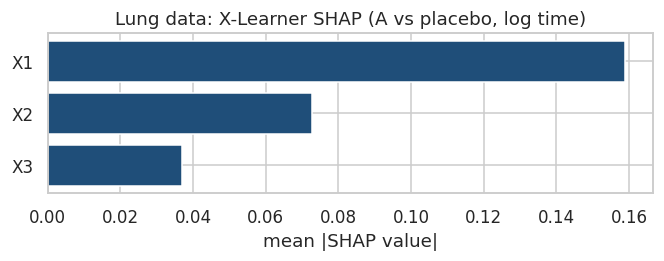

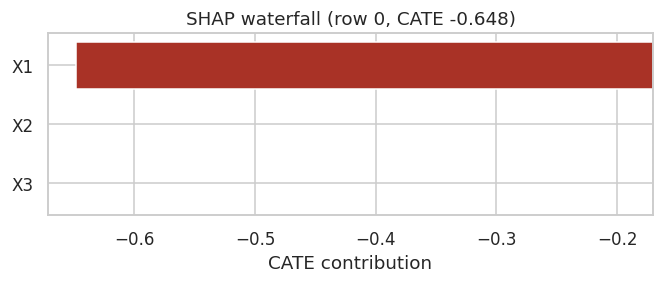

In [14]:
Xc, wc, yc = contrast(X_lung, w_lung, lung["log_time"].to_numpy(dtype=float), 1)
lung_x = XLearner(learner="xgb", n_estimators=N_EST, random_state=5)
lung_x.fit(Xc, wc, yc, feature_names=lung_names)
lung_exp = explain_cate(lung_x, Xc, max_samples=20, n_permutations=5, random_state=5)
lung_exp.plot_importance(title="Lung data: X-Learner SHAP (A vs placebo, log time)")
plt.show()
lung_exp.plot_waterfall(row=0)
plt.show()


#### SHAP (lung): permutation values, `` parallel, and plots


## Summary and conclusions

This tutorial demonstrates how to extend meta-learners for CATE estimation to the multi-arm setting using **PyCausalML** . We cover:
**Part 0** on **PyCausalML** S/T/X/R learners with `simulate_nuisance_and_easy_treatment()` (mode-1 DGP) and a three-level treatment vector; **Part A** on synthetic three-arm data with known contrasts and **X-Learner** / **DR-Learner** pipelines (`learner="rf"`); **Part B** on overlap, balance, calibration, **holdout RMSE**, and a short **decision framework**; **Part C** on **SHAP** for **PyCausalML** per-arm **X-Learner** fits; **Part D** on **`lung`** with simulated **placebo / A / B** arms, outcomes **`log_time`** and **`health_status`**, **S / T / X / R** meta-learners, and **SHAP** for **XGBoost** per-arm **X-Learners**. Multi-arm CATE targets $K-1$ contrasts vs. control; multinomial propensities and per-arm sample size deserve the same diagnostic discipline as in the binary case.

## References

- [CausalML: meta-learners with synthetic data (multiple treatment)](https://causalml.readthedocs.io/en/latest/examples/meta_learners_with_synthetic_data_multiple_treatment.html)
- [CausalML: meta-learners with synthetic data](https://causalml.readthedocs.io/en/latest/examples/meta_learners_with_synthetic_data.html)
- Künzel et al. (2019). Metalearners for estimating heterogeneous treatment effects. *PNAS*.
- Nie & Wager (2021). Quasi-oracle estimation of heterogeneous treatment effects. *Biometrika*.
- Chernozhukov et al. (2018). Double/debiased machine learning. *Econometrica*.
- Kennedy (2020). Towards optimal doubly robust estimation of heterogeneous causal effects. *Statistical Science*.
